# 04 · Modelado de LGD — Benchmark, Champion y Challenger

## Desafío Metodológico: Target Acotado en [0, 1]
Dado que $LGD \in [0, 1]$:
* **Regresión Lineal Clásica (OLS)**: Asume distribución normal no acotada y puede predecir valores negativos o superiores al 100%.
* **Modelo Champion: Fractional Logit (Papke & Wooldridge, 1996)**:

$$E[LGD \mid X] = \frac{1}{1 + e^{-X\beta}}$$

Garantiza matemáticamente estimaciones dentro de $(0, 1)$ manteniendo la interpretabilidad.
* **Modelo Two-Stage Hurdle**: Modela en dos fases la probabilidad de no pérdida y la severidad en caso de quebranto.
* **Modelo Challenger: XGBoost Regressor**: Modelo no lineal basado en árboles con aumento de gradiente.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sys.path.insert(0, str(Path("../src").resolve()))
from model import (
    build_baseline_mean,
    build_linear_lgd,
    build_fractional_logit_lgd,
    build_two_stage_lgd,
    build_xgboost_lgd
)
from evaluation import evaluate_lgd_model

plt.style.use('seaborn-v0_8-whitegrid')

train_df = pd.read_csv("../data/processed/lgd_train_features.csv")
test_df = pd.read_csv("../data/processed/lgd_test_features.csv")

TARGET = "lgd_time"
MODEL_COLS = ['LTV', 'purpose1', 'log_LTV', 'LTV_sq', 'LTV_purpose1']

X_train = train_df[MODEL_COLS]
y_train = train_df[TARGET]
X_test = test_df[MODEL_COLS]
y_test = test_df[TARGET]

print(f"Predictores ({len(MODEL_COLS)}): {MODEL_COLS}")
print(f"Muestra Train: {len(X_train)} | Muestra Test: {len(X_test)}")

Predictores (5): ['LTV', 'purpose1', 'log_LTV', 'LTV_sq', 'LTV_purpose1']
Muestra Train: 1453 | Muestra Test: 364


In [2]:
# 1. Modelo Baseline: Media Histórica
baseline = build_baseline_mean()
baseline.fit(X_train, y_train)
pred_baseline = baseline.predict(X_test)
res_baseline = evaluate_lgd_model(y_test, pred_baseline, "Baseline (Media)")

In [3]:
# 2. Benchmark Lineal (OLS)
ols = build_linear_lgd()
ols.fit(X_train[['LTV']], y_train)
pred_ols = ols.predict(X_test[['LTV']])
res_ols = evaluate_lgd_model(y_test, pred_ols, "Regresión Lineal (OLS)")

In [4]:
# 3. Modelo Champion: Fractional Logit GLM
frac_logit = build_fractional_logit_lgd()
frac_logit.fit(X_train[['LTV', 'purpose1']], y_train)
pred_frac = frac_logit.predict(X_test[['LTV', 'purpose1']])
res_frac = evaluate_lgd_model(y_test, pred_frac, "Fractional Logit (Champion)")

print("--- Resumen Econométrico Fractional Logit ---")
print(frac_logit.results_.summary())

--- Resumen Econométrico Fractional Logit ---
                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                 1453
Model:                            GLM   Df Residuals:                     1450
Model Family:                Binomial   Df Model:                            2
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -710.06
Date:                Wed, 14 Oct 2026   Deviance:                       817.05
Time:                        12:50:19   Pearson chi2:                     769.
No. Iterations:                     4   Pseudo R-squ. (CS):            0.08194
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const 

In [5]:
# 4. Modelo Two-Stage Hurdle
two_stage = build_two_stage_lgd(threshold=0.02)
two_stage.fit(X_train[['LTV', 'purpose1']], y_train)
pred_two_stage = two_stage.predict(X_test[['LTV', 'purpose1']])
res_two_stage = evaluate_lgd_model(y_test, pred_two_stage, "Two-Stage Hurdle")

In [6]:
# 5. Modelo Challenger: XGBoost Regressor
xgb_model = build_xgboost_lgd()
xgb_model.fit(X_train, y_train)
pred_xgb = xgb_model.predict(X_test)
res_xgb = evaluate_lgd_model(y_test, pred_xgb, "XGBoost (Challenger)")

In [7]:
# Tabla Comparativa de Rendimiento en Test
comp_df = pd.DataFrame([
    res_baseline,
    res_ols,
    res_frac,
    res_two_stage,
    res_xgb
])

styled_comp = comp_df[['model', 'mae', 'rmse', 'r2', 'medae', 'mean_pred', 'bias', 'out_of_bounds_pct']].copy()
styled_comp.columns = ['Modelo', 'MAE', 'RMSE', 'R2', 'MedAE', 'LGD Predicha Media', 'Sesgo', '% Fuera de [0, 1]']
display(styled_comp.round(4))

,Modelo,MAE,RMSE,R2,MedAE,LGD Predicha Media,Sesgo,"% Fuera de [0, 1]"
0,Baseline (Media),0.3133,0.3590,-0.0011,0.2945,0.3172,-0.0117,0.0
1,Regresión Lineal (OLS),0.2693,0.3281,0.1637,0.2199,0.3162,-0.0127,0.0
2,Fractional Logit (Champion),0.2683,0.3281,0.1636,0.2179,0.3163,-0.0126,0.0
3,Two-Stage Hurdle,0.2680,0.3280,0.1645,0.2192,0.3137,-0.0151,0.0
4,XGBoost (Challenger),0.2659,0.3302,0.1530,0.1968,0.3185,-0.0104,0.0


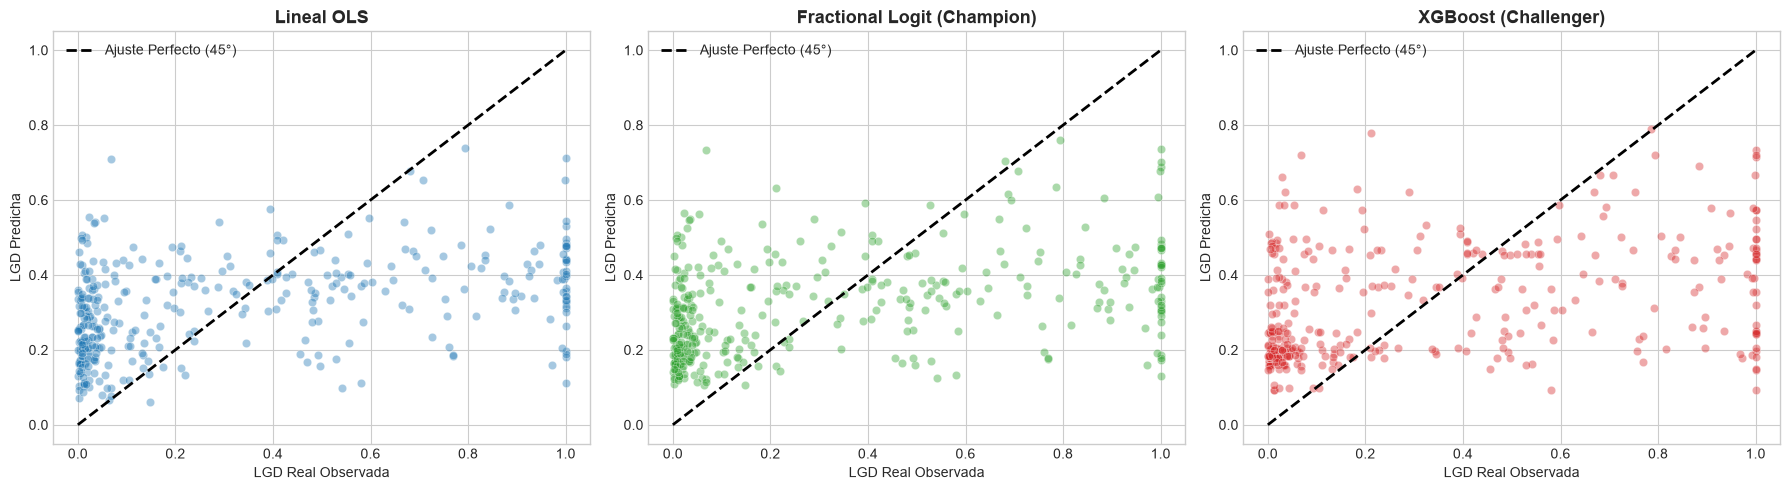

In [8]:
# Gráfico de Predicciones frente a Valores Observados
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

modelos = [
    ("Lineal OLS", pred_ols, axes[0], '#1f77b4'),
    ("Fractional Logit (Champion)", pred_frac, axes[1], '#2ca02c'),
    ("XGBoost (Challenger)", pred_xgb, axes[2], '#d62728')
]

for nombre, preds, ax, col in modelos:
    sns.scatterplot(x=y_test, y=preds, alpha=0.4, color=col, ax=ax)
    ax.plot([0, 1], [0, 1], 'k--', lw=2, label="Ajuste Perfecto (45°)")
    ax.set_title(f"{nombre}", fontsize=13, fontweight='bold')
    ax.set_xlabel("LGD Real Observada")
    ax.set_ylabel("LGD Predicha")
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)
    ax.legend()

plt.tight_layout()
plt.show()

In [9]:
# Guardar modelos serializados
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(frac_logit, models_dir / "champion_fractional_logit.joblib")
joblib.dump(xgb_model, models_dir / "challenger_xgboost.joblib")
joblib.dump(ols, models_dir / "benchmark_ols.joblib")
print(f"Modelos guardados exitosamente en {models_dir.resolve()}.")

Modelos guardados exitosamente en C:\Users\jhon_\Documents\GitHub\IFRS9-Credit-Risk\LGD\models.


## Decisión de Gobernanza y Modelo Champion
* Se selecciona **Fractional Logit como Champion**: respeta de forma estricta las cotas económicas $[0, 1]$, ofrece interpretabilidad completa y coeficiente altamente significativo en LTV ($p < 0.001$).
* **Siguiente Cuaderno**: [05_validation.ipynb](file:///c:/Users/jhon_/Documents/GitHub/IFRS9-Credit-Risk/LGD/notebooks/05_validation.ipynb) evalúa la calibración por deciles de LTV y residuos.